# RAG Retrieval Lab: analysis

Retrieval quality caps every RAG system: the generator can only ground answers in what the retriever returns.
This notebook walks through a controlled benchmark of the usual retrieval decisions, made one at a time on three
BEIR corpora from different domains:

| Corpus | Domain | Documents | Test queries | Dev split (used for tuning) |
|---|---|---:|---:|---|
| SciFact | science claims → abstracts | 5,183 | 300 | train (809 queries) |
| NFCorpus | nutrition / medical | 3,633 | 323 | validation (324) |
| FiQA | personal-finance Q&A | 57,638 | 648 | validation (500) |

Rules followed throughout: every choice (best dense model, fusion weight α) is made on the **dev** split, and
**test** numbers are only reported. Differences are tested with paired bootstrap CIs and sign-flip randomisation
tests over queries, Holm-corrected within each corpus.

Everything below reads the tables written by `scripts/run_pipeline.py`. Run metadata:

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 3)
meta = json.loads((RES / 'run_metadata.json').read_text())
meta['hardware'], meta['timings_s']

({'gpu': 'NVIDIA GeForce RTX 4050 Laptop GPU',
  'cpu': 'Intel64 Family 6 Model 186 Stepping 2, GenuineIntel',
  'platform': 'Windows-11-10.0.26200-SP0'},
 {'load_and_bm25_s': 25.6,
  'dense_and_chunking_s': 213.8,
  'hybrid_s': 6.1,
  'rerank_s': 6579.9,
  'ann_s': 155.9,
  'total_s': 7005.6})

## 1. Headline: every method on every corpus

nDCG@10 on the test split. The tuned hybrid (weighted BM25 + dense) is the best first stage on all three corpora,
and the only reranker that improves on it is GTE-ModernBERT (on FiQA and SciFact).

In [2]:
main = pd.read_csv(RES / 'main_results.csv')
main.pivot(index='method', columns='dataset', values='ndcg@10').sort_values('fiqa')

dataset,fiqa,nfcorpus,scifact
method,,,
BM25,0.251,0.322,0.686
Hybrid + BGE-reranker-base,0.334,0.318,0.718
MiniLM-L6,0.368,0.316,0.645
Hybrid + MiniLM-L6 cross-encoder,0.378,0.355,0.691
Hybrid (RRF),0.379,0.373,0.731
E5-base,0.400,0.355,0.721
BGE-small,0.403,0.343,0.713
BGE-base,0.406,0.374,0.742
BM25 + GTE-reranker-ModernBERT,0.429,0.349,0.760


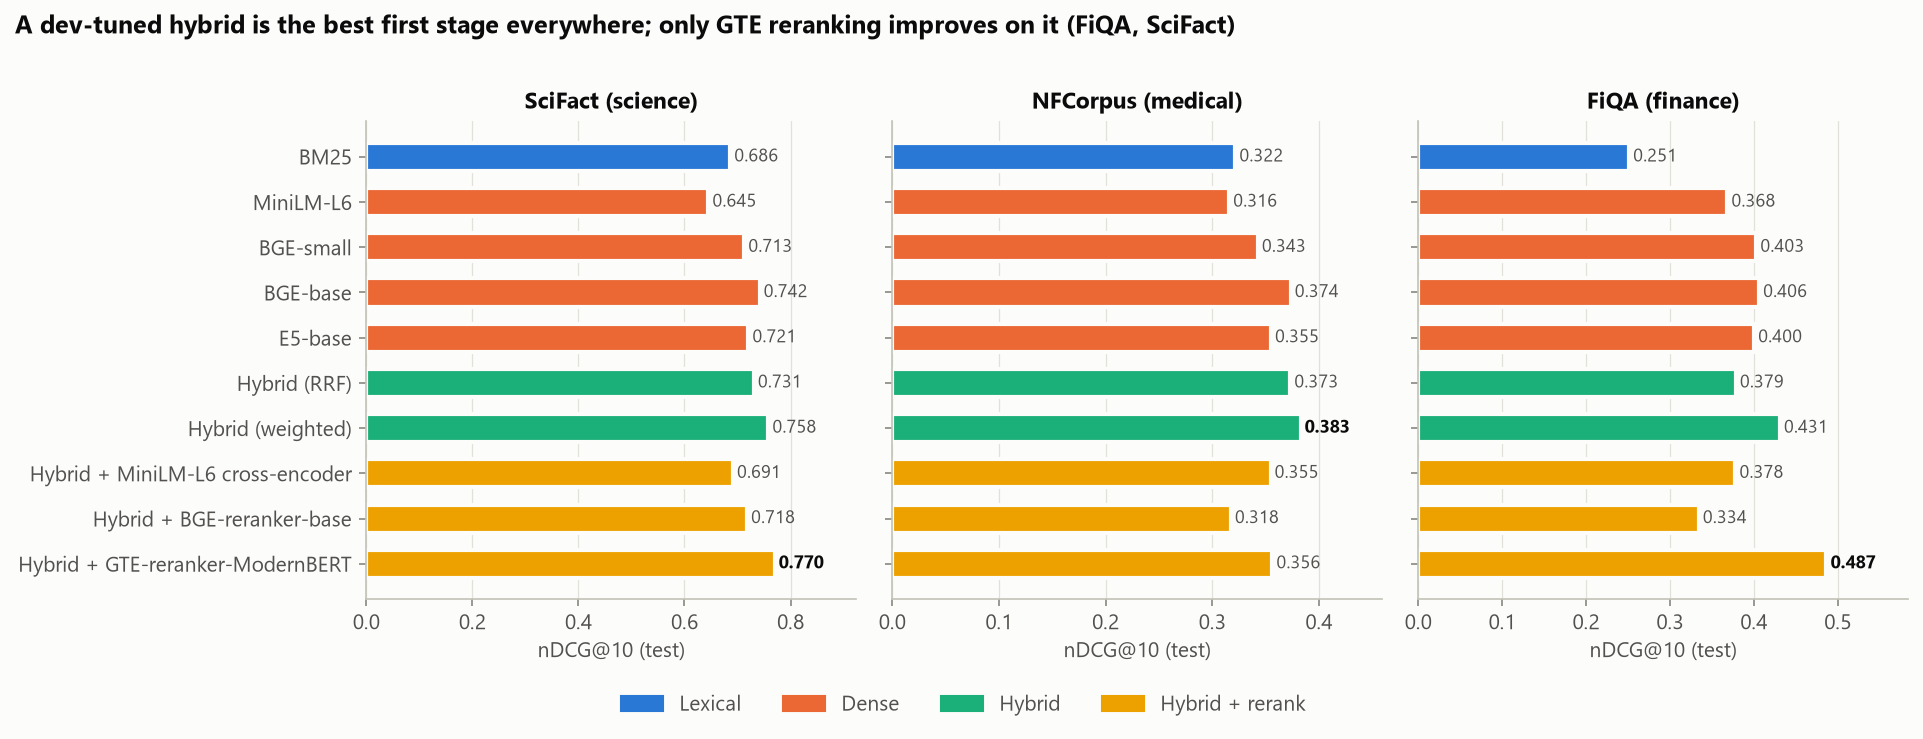

In [3]:
display(Image(FIG / '01_ndcg_by_method.png'))

## 2. Does this pipeline reproduce published numbers?

Before trusting any comparison, the single-retriever baselines are checked against independent references:
the official MTEB results repository for the dense models (fetched at run time) and the BEIR paper for BM25.

All 12 dense-model scores land within ±0.002 of MTEB, so the encoding, prefixes and metrics are right.
BM25 differs by up to 0.02 because this project uses `bm25s` on concatenated title + text, while BEIR used
Elasticsearch multi-field BM25.

In [4]:
pd.read_csv(RES / 'published_comparison.csv').drop(columns='source')

,dataset,model,ours,published,diff
0,scifact,BM25,0.686,0.665,2.130e-02
1,nfcorpus,BM25,0.322,0.325,-3.300e-03
2,fiqa,BM25,0.251,0.236,1.540e-02
3,scifact,MiniLM-L6,0.645,0.645,0.000e+00
4,nfcorpus,MiniLM-L6,0.316,0.316,-0.000e+00
5,fiqa,MiniLM-L6,0.368,0.369,-2.000e-04
6,scifact,BGE-small,0.713,0.713,0.000e+00
7,nfcorpus,BGE-small,0.343,0.343,1.000e-04
8,fiqa,BGE-small,0.403,0.403,-4.000e-04
9,scifact,BGE-base,0.742,0.744,-1.700e-03


## 3. Hybrid fusion: weighted beats reciprocal rank fusion

Weighted fusion min-max normalises BM25 and dense scores over the union of both top-100 lists and mixes them with
weight α on the dense side. α is chosen on the dev split; the dashed test curve is shown only to check that the
choice transfers.

* The dev-chosen α (0.8 / 0.7 / 0.8) is exactly the test-optimal α on all three corpora.
* Reciprocal rank fusion (RRF, k = 60) needs no tuning but is significantly worse than tuned weighted fusion
  everywhere, and on FiQA (where BM25 is weak) it falls below dense-only retrieval.

In [5]:
sweep = pd.read_csv(RES / 'hybrid_alpha_sweep.csv')
sweep[sweep.chosen & (sweep.split == 'test')][['dataset', 'dense_model', 'alpha', 'ndcg@10', 'recall@100']]

,dataset,dense_model,alpha,ndcg@10,recall@100
19,scifact,BGE-base,0.8,0.758,0.977
40,nfcorpus,BGE-base,0.7,0.383,0.344
63,fiqa,E5-base,0.8,0.431,0.752


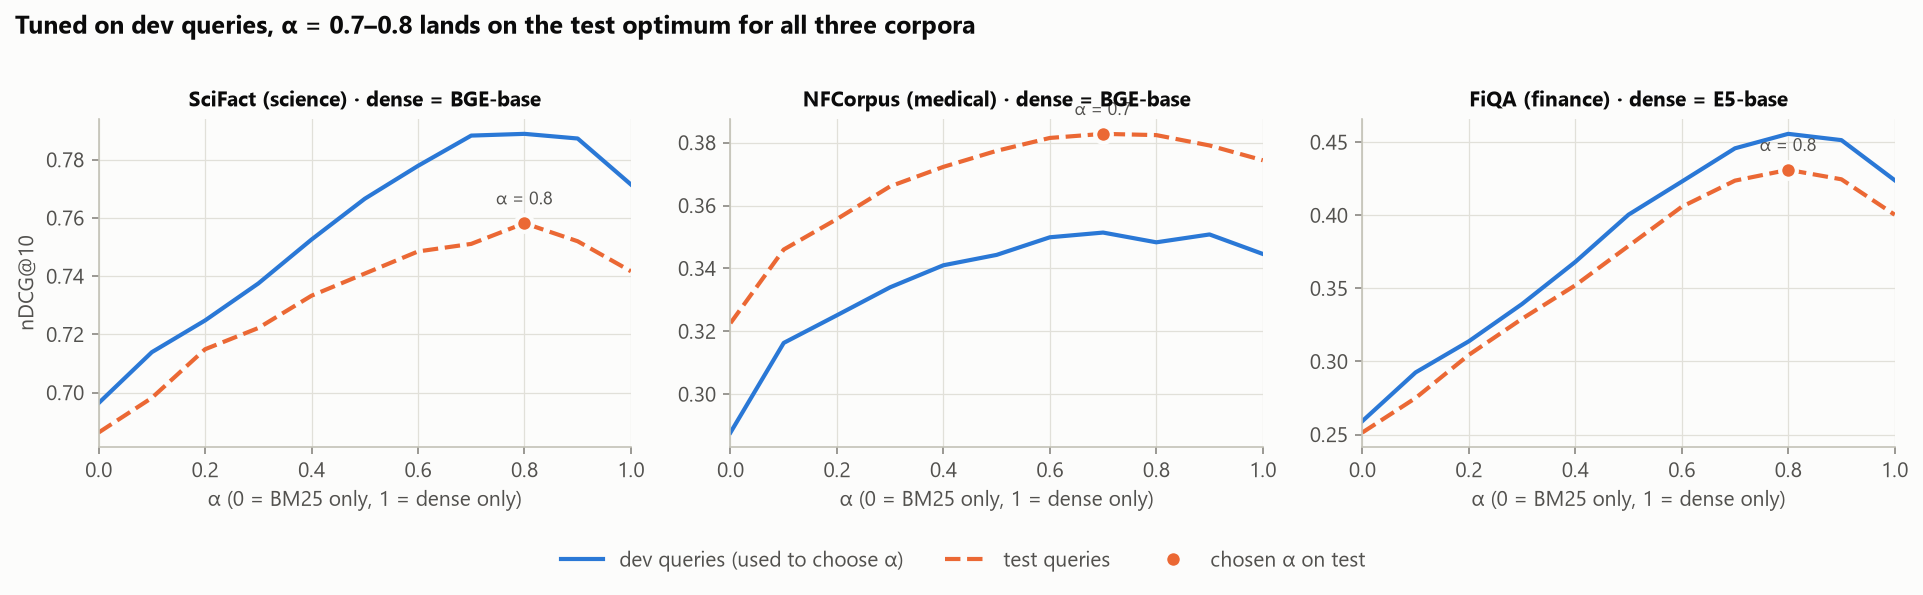

In [6]:
display(Image(FIG / '02_hybrid_alpha_sweep.png'))

## 4. Cross-encoder reranking: the model matters more than the decision to rerank

Three cross-encoders rerank the top-k hybrid candidates. Two widely used ones (MS MARCO MiniLM-L6 and
BGE-reranker-base) make every corpus *worse*, and the damage grows with rerank depth: their own relevance
judgments are weaker than the hybrid ranking they replace. GTE-reranker-ModernBERT improves FiQA by +0.056
(continuing to gain with depth), is a wash on SciFact and hurts NFCorpus beyond the top 10.

Latency is the other cost: on a laptop RTX 4050, GTE takes ~1.7 s per query at top-100 but ~0.16 s at top-10.

In [7]:
pd.read_csv(RES / 'rerank_depth.csv').sort_values(['reranker', 'dataset', 'depth'])

,dataset,reranker,depth,p50_ms,p95_ms,ndcg@10,recall@100,mrr@10
29,fiqa,BGE-reranker-base,0,0.000,0.000,0.431,0.752,0.507
25,fiqa,BGE-reranker-base,10,85.113,92.002,0.415,0.752,0.479
26,fiqa,BGE-reranker-base,20,150.919,180.012,0.387,0.752,0.458
27,fiqa,BGE-reranker-base,50,403.160,447.806,0.356,0.752,0.426
28,fiqa,BGE-reranker-base,100,885.486,926.376,0.334,0.752,0.400
24,nfcorpus,BGE-reranker-base,0,0.000,0.000,0.383,0.344,0.581
20,nfcorpus,BGE-reranker-base,10,77.874,83.633,0.369,0.344,0.566
21,nfcorpus,BGE-reranker-base,20,155.912,162.694,0.346,0.344,0.563
22,nfcorpus,BGE-reranker-base,50,392.174,400.401,0.332,0.344,0.557
23,nfcorpus,BGE-reranker-base,100,802.465,839.443,0.318,0.344,0.542


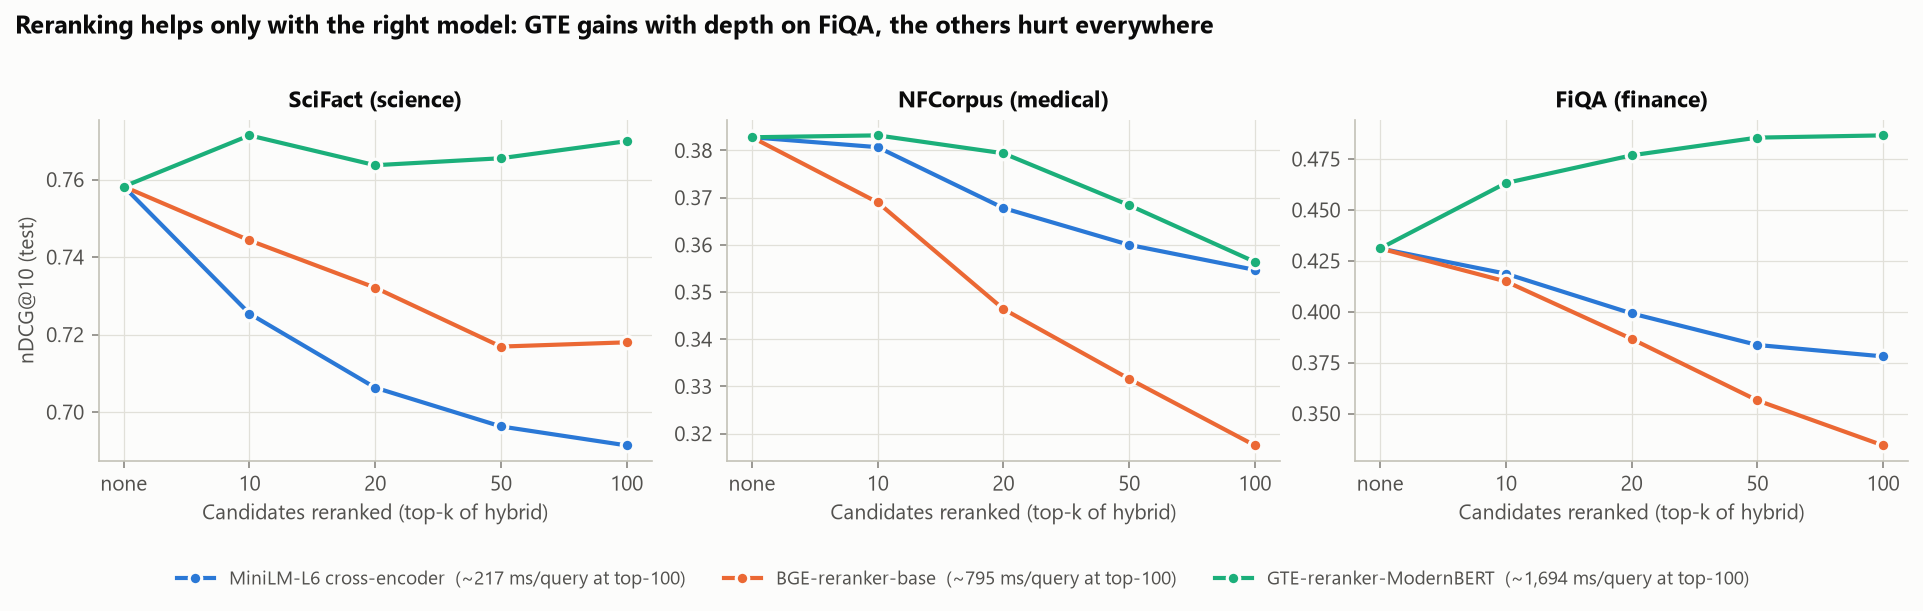

In [8]:
display(Image(FIG / '03_rerank_depth.png'))

## 5. Chunking: only worth it when documents don't fit the encoder

Documents were split into 64/128/256-word windows (25% overlap, title prepended), embedded, and scored by their
best chunk (MaxP). The first table shows how many whole documents each encoder silently truncates.

MiniLM-L6 truncates 71-79% of SciFact and NFCorpus abstracts at its 256-token limit, and 64-word chunks recover
+0.03 / +0.02 nDCG@10 there. BGE-small (512 tokens) truncates under 10%, and chunking moves it by at most +0.01 on
those abstracts. On FiQA's short forum posts, 64-word chunks fragment answers and hurt both models (−0.03 to −0.05). These are effect sizes from
single runs, without CIs.

In [9]:
display(pd.read_csv(RES / 'doc_lengths.csv'))
pd.read_csv(RES / 'chunking.csv').pivot_table(index=['model', 'chunk_words'], columns='dataset', values='ndcg@10')

,dataset,model,max_seq_length,median_tokens,p90_tokens,share_truncated
0,scifact,MiniLM-L6,256,316.0,502.0,0.710
1,nfcorpus,MiniLM-L6,256,357.0,504.8,0.788
2,fiqa,MiniLM-L6,256,120.0,371.0,0.192
3,scifact,BGE-small,512,316.0,502.0,0.088
4,nfcorpus,BGE-small,512,357.0,504.8,0.091
5,fiqa,BGE-small,512,120.0,371.0,0.042
6,scifact,BGE-base,512,316.0,502.0,0.088
7,nfcorpus,BGE-base,512,357.0,504.8,0.091
8,fiqa,BGE-base,512,120.0,371.0,0.042
9,scifact,E5-base,512,318.0,504.0,0.090


dataset                 fiqa  nfcorpus  scifact
model     chunk_words                          
BGE-small 0            0.403     0.343    0.713
          64           0.356     0.353    0.711
          128          0.382     0.350    0.716
          256          0.400     0.344    0.715
MiniLM-L6 0            0.368     0.316    0.645
          64           0.340     0.332    0.676
          128          0.379     0.327    0.666
          256          0.374     0.317    0.645

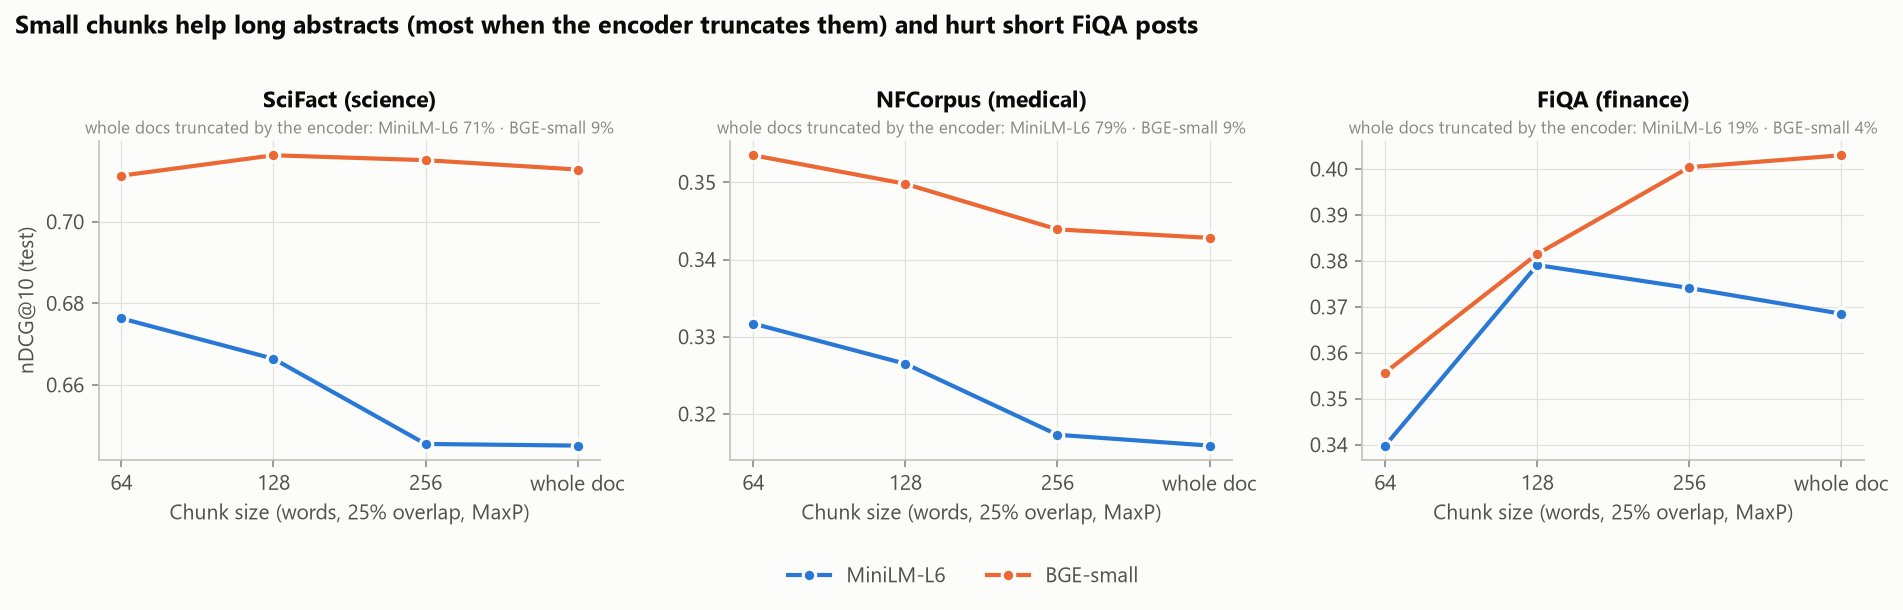

In [10]:
display(Image(FIG / '04_chunk_size.png'))

## 6. Approximate nearest-neighbour indexes

On the 57,638 FiQA vectors (BGE-base, 768-d), exact search takes ~16 ms per query on one CPU thread.

* **HNSW** (M = 32) recovers 98.8% of the exact top-10 at efSearch = 128 in 0.42 ms (~37× faster), for a
  −0.007 nDCG@10 change.
* **IVF-PQ** shrinks the index 25× (169 → 6.8 MB) but recall saturates near 0.52 and nDCG@10 drops by 0.09.
  Re-scoring a PQ shortlist with the exact vectors ("refine") restores 0.90 recall, but needs the full vectors again.
* **SQ8** cuts memory 4× with no measurable quality loss; in this faiss-cpu build it was slower than flat search.

In [11]:
pd.read_csv(RES / 'ann_benchmark.csv')

,n_vectors,dim,index,param,value,neighbour_recall@10,ndcg@10,p50_ms,p95_ms,size_mb,build_s
0,57638,768,Flat,-,0,1.000,0.406,15.755,19.516,168.861,0.081
1,57638,768,SQ8,-,0,0.993,0.406,36.285,46.187,42.221,0.122
2,57638,768,HNSW,efSearch,16,0.864,0.374,0.086,0.130,183.824,35.646
3,57638,768,HNSW,efSearch,32,0.932,0.387,0.132,0.188,183.824,35.646
4,57638,768,HNSW,efSearch,64,0.969,0.398,0.233,0.352,183.824,35.646
5,57638,768,HNSW,efSearch,128,0.988,0.399,0.421,0.609,183.824,35.646
6,57638,768,HNSW,efSearch,256,0.996,0.403,1.228,1.908,183.824,35.646
7,57638,768,IVF-Flat,nprobe,1,0.379,0.216,0.079,0.098,172.309,2.856
8,57638,768,IVF-Flat,nprobe,4,0.666,0.316,0.117,0.141,172.309,2.856
9,57638,768,IVF-Flat,nprobe,16,0.872,0.370,0.230,0.288,172.309,2.856


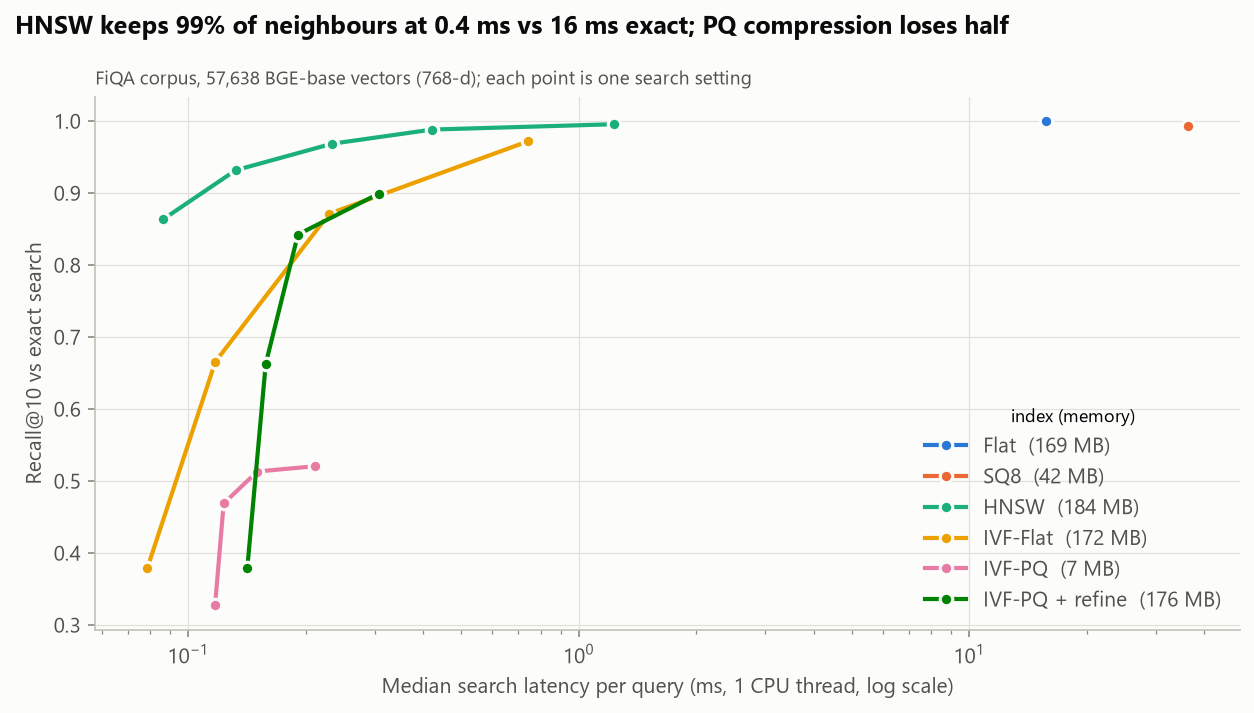

In [12]:
display(Image(FIG / '05_ann_index_tradeoff.png'))

## 7. When does BM25 beat dense retrieval?

Hypothesis going in: BM25 should win on queries that contain a rare, exact term (tickers, drug names, acronyms).
Queries were split into terciles of their rarest term's IDF.

The data does not support it: the dense model's advantage is positive in every tercile on every corpus, and is not
smaller for high-specificity queries. BM25 still wins on 10-33% of individual queries, which is why fusing the two
helps.

In [13]:
spec = pd.read_csv(RES / 'query_specificity.csv')
spec.assign(delta=spec.dense - spec.bm25).groupby(['dataset', 'specificity'], observed=True)['delta'].agg(['mean', 'count', lambda d: (d < 0).mean()]).rename(columns={'<lambda_0>': 'share_bm25_better'})

mean  count  share_bm25_better
dataset  specificity                                 
fiqa     high         0.150    216              0.162
         low          0.116    216              0.185
         medium       0.181    216              0.139
nfcorpus high         0.058    108              0.167
         low          0.048    108              0.287
         medium       0.049    107              0.327
scifact  high         0.059    100              0.100
         low          0.062    100              0.130
         medium       0.045    100              0.200

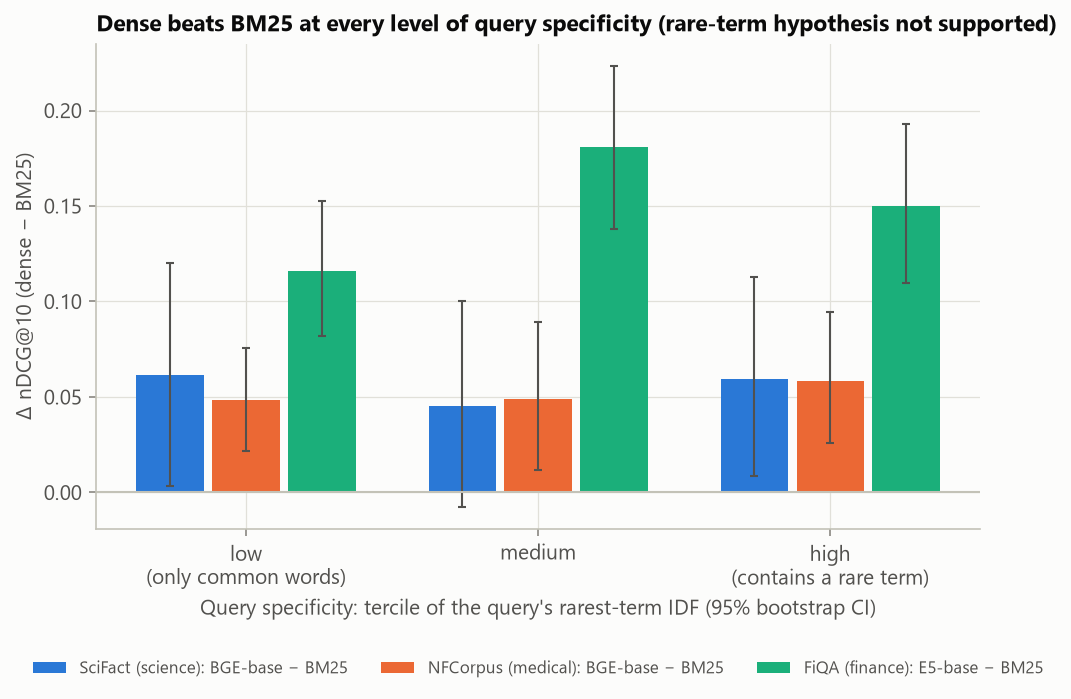

In [14]:
display(Image(FIG / '06_query_specificity.png'))

## 8. Significance tests

Per-query nDCG@10 differences (system − baseline): mean, 95% bootstrap CI, two-sided sign-flip randomisation p-value
(10,000 resamples) and Holm-adjusted p within each corpus. The minimum reportable p is ~0.0001.

In [15]:
pd.read_csv(RES / 'significance.csv')

,dataset,baseline,system,mean_diff,ci_low,ci_high,p_value,p_holm
0,scifact,BM25,BGE-base,0.055,2.350e-02,8.710e-02,8.000e-04,0.006
1,scifact,BGE-base,Hybrid (weighted),0.017,3.100e-03,3.020e-02,1.780e-02,0.071
2,scifact,Hybrid (weighted),Hybrid (RRF),-0.027,-4.470e-02,-1.080e-02,1.800e-03,0.011
3,scifact,Hybrid (weighted),Hybrid + MiniLM-L6 cross-encoder,-0.067,-9.620e-02,-3.820e-02,1.000e-04,0.001
4,scifact,Hybrid (weighted),Hybrid + BGE-reranker-base,-0.040,-6.790e-02,-1.180e-02,3.800e-03,0.019
5,scifact,Hybrid (weighted),Hybrid + GTE-reranker-ModernBERT,0.012,-1.710e-02,4.090e-02,4.215e-01,0.547
6,scifact,BGE-base,Hybrid + GTE-reranker-ModernBERT,0.028,-1.800e-03,5.930e-02,7.490e-02,0.225
7,scifact,Hybrid + MiniLM-L6 cross-encoder,Hybrid + GTE-reranker-ModernBERT,0.079,4.790e-02,1.091e-01,1.000e-04,0.001
8,scifact,Hybrid + BGE-reranker-base,Hybrid + GTE-reranker-ModernBERT,0.052,2.340e-02,8.150e-02,6.000e-04,0.005
9,scifact,Hybrid + GTE-reranker-ModernBERT,BM25 + GTE-reranker-ModernBERT,-0.009,-2.690e-02,6.300e-03,2.738e-01,0.547


## Takeaways for building a RAG retriever

1. **Measure before tuning.** The popular default embedding (MiniLM-L6) scores *below* BM25 on two of three corpora.
2. **Use hybrid retrieval, and tune its weight** on a small labelled dev set. Here α ≈ 0.7-0.8 transferred exactly
   to test; untuned RRF left 0.01-0.05 nDCG@10 on the table.
3. **Evaluate rerankers on your own data before shipping one.** Two of three popular cross-encoders made results
   worse. If you rerank, start shallow (top-10/20) and only go deeper if it keeps paying off.
4. **The first stage still matters after reranking:** on FiQA, the same reranker on BM25 candidates scored 0.057
   lower than on hybrid candidates, because it cannot recover documents BM25 never retrieved.
5. **Chunk to fit the encoder,** not by habit.
6. **HNSW is the default ANN choice** at this scale; product quantization needs a refine step to be usable.